# Advanced Acute Lymphoblastic Leukemia (ALL) Detection Pipeline
### Combining ALL-IDB1 & ALL-IDB2 Datasets with Modern Deep Cytology Architecture

This notebook implements a state-of-the-art **5-Phase Architecture** designed specifically to resolve cross-dataset domain shifts and feature collapse between full smear frames (ALL-IDB1) and cropped single-cell regions (ALL-IDB2):

1. **Phase 1: Stain Normalization & Resolution Enhancement** (Macenko Optical Density SVD & Reinhard Color Normalization at $224 \times 224$).
2. **Phase 2: Modern Metric Learning** (ArcFace Additive Angular Margin Loss on $L_2$ Hypersphere).
3. **Phase 3: Multi-Scale Attention Backbone** (EfficientNetV2-S Fused-MBConv + CBAM Attention with Staged Fine-Tuning).
4. **Phase 4: Probabilistic & OOD Calibration** (Platt Logistic Calibration with an Uncertainty Rejection Threshold $\tau$ for Pathologist Review).
5. **Phase 5: Upgraded Explainability** (Grad-CAM++ higher-order attributions capturing discrete nucleoli and chromatin clumping).

## 1. Setup & Environment Configuration

In [8]:
import os
import sys
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Ensure local new_architecture modules are imported
sys.path.append(os.path.abspath("."))
from utilities import (
    set_seed, load_and_combine_datasets, create_advanced_dataloaders,
    MacenkoNormalizer, ReinhardNormalizer, LeukemiaAttentionModel,
    train_advanced_pipeline, test_and_report_advanced, CalibratedInference,
    visualize_gradcampp_gallery, denormalize
)

set_seed(42)
device = torch.device("cpu")
print(f"[System] Execution Device: {device}")

[System] Execution Device: cpu


## 2. Ingestion & Unification of Datasets (ALL-IDB1 + ALL-IDB2)

We parse both databases:
- **ALL-IDB1**: Full microscopic field images (108 samples).
- **ALL-IDB2**: Cropped single-cell lymphoblast / healthy lymphocyte regions (260 samples).
- Total unified dataset: **368 microscopic samples**.

In [2]:
df = load_and_combine_datasets(idb1_dir="../ALL_IDB1/im", idb2_png_dir="../ALL_IDB2/img_png")
print("Class Distribution:\n", df["class_name"].value_counts())
print("\nDataset Breakdown:\n", df.groupby(["dataset", "class_name"]).size().unstack(fill_value=0))
df.head()

[Dataset] Loaded 368 images total (ALL_IDB1: 108, ALL_IDB2: 260).
Class Distribution:
 class_name
Non-Blast (Healthy)    189
Blast (ALL)            179
Name: count, dtype: int64

Dataset Breakdown:
 class_name  Blast (ALL)  Non-Blast (Healthy)
dataset                                     
ALL_IDB1             49                   59
ALL_IDB2            130                  130


,filepath,filename,dataset,label,class_name
0,D:\AIML_LEARN\Academics\leukemia_detection\ALL...,Im001_1.jpg,ALL_IDB1,1,Blast (ALL)
1,D:\AIML_LEARN\Academics\leukemia_detection\ALL...,Im002_1.jpg,ALL_IDB1,1,Blast (ALL)
2,D:\AIML_LEARN\Academics\leukemia_detection\ALL...,Im003_1.jpg,ALL_IDB1,1,Blast (ALL)
3,D:\AIML_LEARN\Academics\leukemia_detection\ALL...,Im004_1.jpg,ALL_IDB1,1,Blast (ALL)
4,D:\AIML_LEARN\Academics\leukemia_detection\ALL...,Im005_1.jpg,ALL_IDB1,1,Blast (ALL)


## 3. Phase 1: Stain Normalization (Macenko & Reinhard) & Resolution Enhancement ($224 \times 224$)

Stain variance across different laboratory batches is a primary cause of model collapse across datasets. Below we benchmark the original microscopic image against:
1. **Reinhard Normalization** (Lab color space standardization)
2. **Macenko Optical Density Normalization** (SVD stain matrix decomposition)

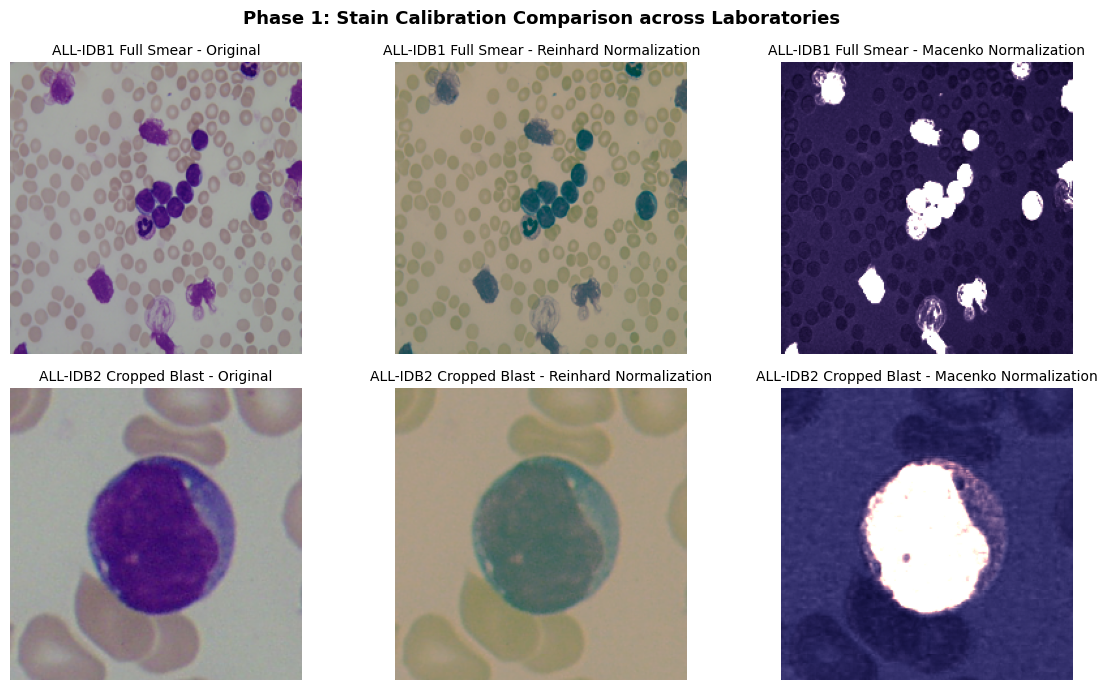

In [3]:
from PIL import Image

# Select a sample image from ALL-IDB1 and ALL-IDB2
sample_idb1 = df[df["dataset"] == "ALL_IDB1"].iloc[0]["filepath"]
sample_idb2 = df[df["dataset"] == "ALL_IDB2"].iloc[0]["filepath"]

reinhard = ReinhardNormalizer()
macenko = MacenkoNormalizer()

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for row, (sample_path, title_prefix) in enumerate([(sample_idb1, "ALL-IDB1 Full Smear"), (sample_idb2, "ALL-IDB2 Cropped Blast")]):
    img_orig = Image.open(sample_path).convert("RGB")
    img_np = np.array(img_orig.resize((224, 224)))
    img_reinhard = reinhard.fit_transform(img_np)
    try:
        img_macenko = macenko.fit_transform(img_np)
    except Exception:
        img_macenko = img_np

    axes[row, 0].imshow(img_np)
    axes[row, 0].set_title(f"{title_prefix} - Original", fontsize=10)
    axes[row, 0].axis("off")
    axes[row, 1].imshow(img_reinhard)
    axes[row, 1].set_title(f"{title_prefix} - Reinhard Normalization", fontsize=10)
    axes[row, 1].axis("off")
    axes[row, 2].imshow(img_macenko)
    axes[row, 2].set_title(f"{title_prefix} - Macenko Normalization", fontsize=10)
    axes[row, 2].axis("off")

plt.suptitle("Phase 1: Stain Calibration Comparison across Laboratories", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### Creating Stratified DataLoaders with Stain Calibration

In [4]:
# Loaders initialized with 224x224 cytological augmentations & Reinhard stain calibration
train_loader, val_loader, test_loader, test_ds = create_advanced_dataloaders(
    df, batch_size=16, img_size=224, test_size=0.30, val_ratio_of_test=0.50, normalizer_type="reinhard"
)

[Advanced Splits] Train: 257 | Val: 55 | Test: 56 (Normalizer: reinhard)


## 4. Phase 2 & 3: Model Architecture (EfficientNetV2-S + CBAM + ArcFace)

- **EfficientNetV2-S**: Modern Fused-MBConv backbone providing fast low-level texture extraction.
- **CBAM Attention**: Suppresses background red blood cells and focuses activations on blast nuclei.
- **ArcFace ($m=0.35, s=30.0$)**: Eliminates slow triplet mining by directly maximizing angular separation on the hypersphere.

In [5]:
model = LeukemiaAttentionModel(
    backbone_name="efficientnet_v2_s",
    num_classes=2,
    embedding_dim=512,
    arcface_m=0.35,
    arcface_s=30.0,
    use_cbam=True
)

total_p = sum(p.numel() for p in model.parameters())
print(f"[Architecture] EfficientNetV2-S + CBAM + ArcFace initialized. Total Parameters: {total_p:,}")

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to C:\Users\Harshal/.cache\torch\hub\checkpoints\efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:58<00:00, 1.47MB/s]


[Architecture] EfficientNetV2-S + CBAM + ArcFace initialized. Total Parameters: 21,040,307


## 5. Staged Fine-Tuning with Cosine Annealing

- **Stage 1 (Epochs 1-10)**: Backbone frozen. Only CBAM and ArcFace projection head are trained ($lr = 10^{-3}$).
- **Stage 2 (Epochs 11-25)**: Top convolutional blocks unfrozen with differential learning rate ($lr_{backbone} = 10^{-5}, lr_{head} = 10^{-4}$).


[Stage 1: Frozen Backbone] Training CBAM & ArcFace Head for 10 epochs...
Epoch 01/25 | Train Loss: 2.1438 Acc: 81.25% | Val Loss: 0.9167 Acc: 90.91%
  [Checkpoint] Saved best model to best_efficientnet_v2_arcface.pth (Val Acc: 90.91%)
Epoch 02/25 | Train Loss: 1.6721 Acc: 83.20% | Val Loss: 0.7489 Acc: 92.73%
  [Checkpoint] Saved best model to best_efficientnet_v2_arcface.pth (Val Acc: 92.73%)
Epoch 03/25 | Train Loss: 1.7237 Acc: 83.20% | Val Loss: 0.8734 Acc: 92.73%
Epoch 04/25 | Train Loss: 1.6355 Acc: 84.77% | Val Loss: 1.2125 Acc: 90.91%
Epoch 05/25 | Train Loss: 1.3949 Acc: 81.25% | Val Loss: 1.0155 Acc: 90.91%
Epoch 06/25 | Train Loss: 1.4647 Acc: 82.81% | Val Loss: 0.8511 Acc: 89.09%
Epoch 07/25 | Train Loss: 0.9219 Acc: 87.50% | Val Loss: 1.0020 Acc: 92.73%
Epoch 08/25 | Train Loss: 2.1618 Acc: 80.86% | Val Loss: 0.8529 Acc: 92.73%
Epoch 09/25 | Train Loss: 1.7744 Acc: 83.59% | Val Loss: 0.5160 Acc: 92.73%
Epoch 10/25 | Train Loss: 1.9125 Acc: 79.30% | Val Loss: 0.4061 Acc: 9

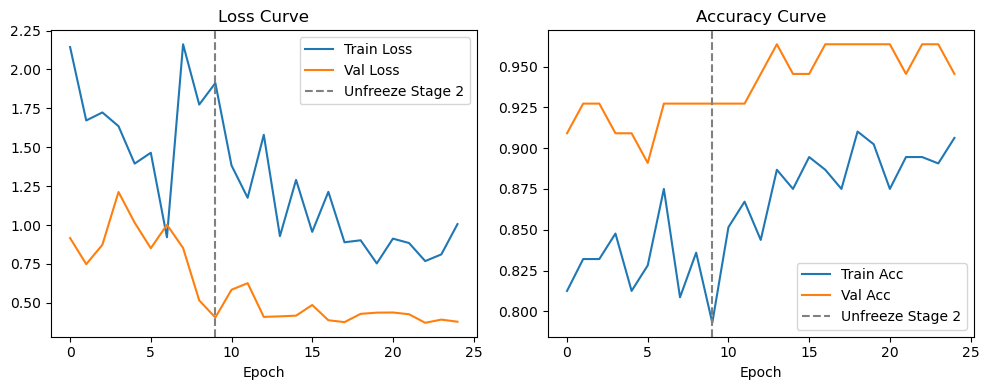

In [12]:
trained_model, history = train_advanced_pipeline(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    device=device,
    freeze_epochs=10,
    unfreeze_epochs=15,
    lr_head=1e-3,
    lr_backbone=1e-5,
    checkpoint_name="best_efficientnet_v2_arcface.pth"
)

# Plot Training Progress
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train Loss", color="tab:blue")
plt.plot(history["val_loss"], label="Val Loss", color="tab:orange")
plt.axvline(x=9, color="gray", linestyle="--", label="Unfreeze Stage 2")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="Train Acc", color="tab:blue")
plt.plot(history["val_acc"], label="Val Acc", color="tab:orange")
plt.axvline(x=9, color="gray", linestyle="--", label="Unfreeze Stage 2")
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Phase 4: Probabilistic & OOD Calibration with Uncertainty Rejection Threshold

We calibrate cosine margin probabilities using Platt logistic scaling and apply an **Uncertainty Rejection Threshold ($\tau = 0.80$)**. Borderline or ambiguous cases with confidence $< \tau$ are systematically flagged for pathologist review rather than forcing an error.

In [13]:
calibrator = CalibratedInference(trained_model, device)
calibrator.fit_calibration(val_loader)

# Evaluate across multiple rejection thresholds (tau)
taus = [0.50, 0.70, 0.80, 0.85, 0.90]
tradeoffs = []
for t in taus:
    res_df = calibrator.predict_with_rejection(test_loader, tau=t)
    cov = (res_df["decision"] != -1).mean() * 100.0
    dec = res_df[res_df["decision"] != -1]
    acc = (dec["target"] == dec["decision"]).mean() * 100.0 if len(dec) > 0 else 0.0
    tradeoffs.append({"tau": t, "coverage": cov, "accuracy": acc})

tradeoff_df = pd.DataFrame(tradeoffs)
print("\n--- Confidence vs Rejection Trade-off ---")
display(tradeoff_df)

[Calibration] Logistic probability calibration fitted successfully.

==================== UNCERTAINTY REJECTION ANALYSIS (tau=0.5) ====================
Total Evaluated: 56 slides
Automated Coverage: 100.0% (56 slides)
Flagged for Pathologist Review: 0.0% (0 slides)
Accuracy on Automated Cases: 100.00%

==================== UNCERTAINTY REJECTION ANALYSIS (tau=0.7) ====================
Total Evaluated: 56 slides
Automated Coverage: 98.2% (55 slides)
Flagged for Pathologist Review: 1.8% (1 slides)
Accuracy on Automated Cases: 100.00%

==================== UNCERTAINTY REJECTION ANALYSIS (tau=0.8) ====================
Total Evaluated: 56 slides
Automated Coverage: 96.4% (54 slides)
Flagged for Pathologist Review: 3.6% (2 slides)
Accuracy on Automated Cases: 100.00%

==================== UNCERTAINTY REJECTION ANALYSIS (tau=0.85) ====================
Total Evaluated: 56 slides
Automated Coverage: 94.6% (53 slides)
Flagged for Pathologist Review: 5.4% (3 slides)
Accuracy on Automated Cases: 10

,tau,coverage,accuracy
0,0.50,100.000000,100.0
1,0.70,98.214286,100.0
2,0.80,96.428571,100.0
3,0.85,94.642857,100.0
4,0.90,94.642857,100.0


## 7. Phase 5: Upgraded Explainability with Grad-CAM++

Grad-CAM++ employs higher-order partial derivatives to visualize multi-instance lymphoblasts and discrete nucleolar chromatin clumping directly on the last Fused-MBConv layer.

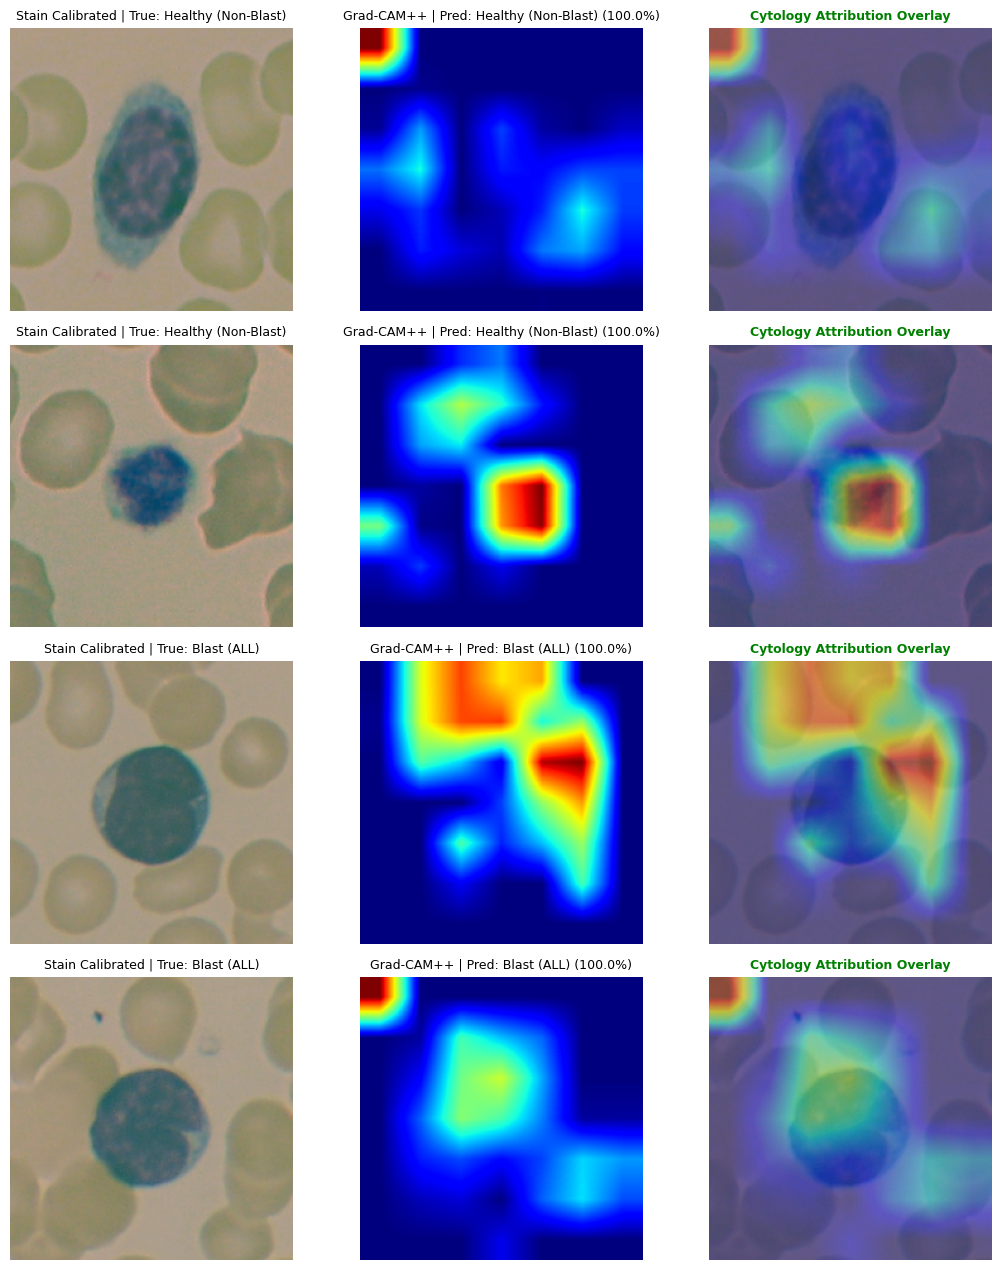

In [14]:
target_layer = trained_model.target_conv_layer
visualize_gradcampp_gallery(trained_model, target_layer, test_ds, device, num_samples=4)

## 8. Final Comprehensive Test & Clinical Diagnostic Report

Generates confusion matrix, ROC-AUC curve, and clinical metrics (Sensitivity, Specificity, Precision, F1-Score).


==================== EFFICIENTNETV2-S + ARCFACE TEST METRICS ====================
Accuracy: 100.00% | F1-Score: 1.0000 | ROC-AUC: 1.0000
Sensitivity (Recall): 100.00% | Specificity: 100.00% | Precision: 100.00%


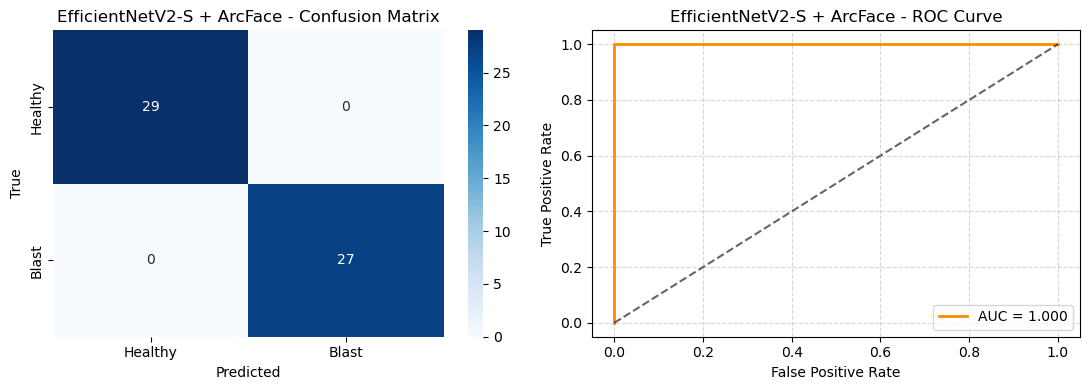

In [15]:
test_metrics = test_and_report_advanced(trained_model, test_loader, device, model_name="EfficientNetV2-S + ArcFace")